# Experiment 4: Implementation of Regression Models with Regularization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (353, 10) Test shape: (89, 10)


In [3]:
lr = LinearRegression()
lr.fit(X_train, y_train)
ridge = Ridge(alpha=10.0)
ridge.fit(X_train, y_train)
lasso = Lasso(alpha=1.0)
lasso.fit(X_train, y_train)

models = ['Linear', 'Ridge', 'Lasso']
preds = [lr.predict(X_test), ridge.predict(X_test), lasso.predict(X_test)]
mses = []
r2s = []
for name, pred in zip(models, preds):
    m = mean_squared_error(y_test, pred)
    r = r2_score(y_test, pred)
    mses.append(m)
    r2s.append(r)
    print(name, "-> MSE:", round(m, 2), "| R2:", round(r, 4))

Linear -> MSE: 2900.19 | R2: 0.4526
Ridge -> MSE: 2875.78 | R2: 0.4572
Lasso -> MSE: 2824.57 | R2: 0.4669


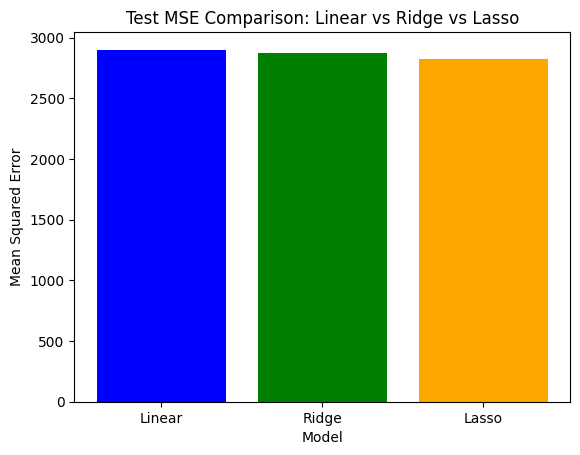

In [4]:
plt.bar(models, mses, color=['blue', 'green', 'orange'])
plt.title('Test MSE Comparison: Linear vs Ridge vs Lasso')
plt.xlabel('Model')
plt.ylabel('Mean Squared Error')
plt.show()

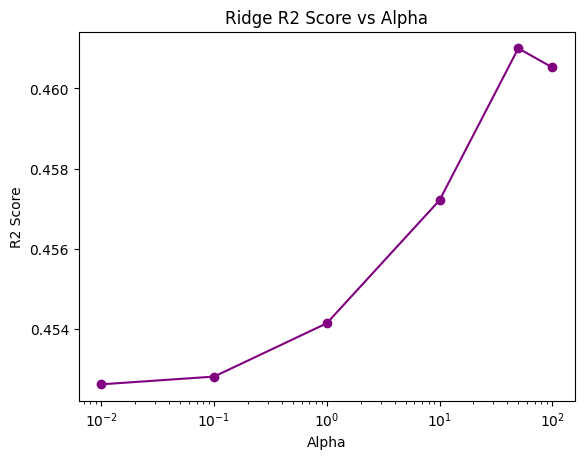

In [5]:
alphas = [0.01, 0.1, 1, 10, 50, 100]
ridge_scores = []
for a in alphas:
    m = Ridge(alpha=a)
    m.fit(X_train, y_train)
    ridge_scores.append(r2_score(y_test, m.predict(X_test)))

plt.plot(alphas, ridge_scores, marker='o', color='purple')
plt.xscale('log')
plt.title('Ridge R2 Score vs Alpha')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.show()